In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import RocCurveDisplay
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

In [2]:
url = "https://raw.githubusercontent.com/venzera/KIBAI/refs/heads/main/cancer.csv"
df = pd.read_csv(url)
display(df)

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,M,69,1,2,2,1,1,2,1,2,2,2,2,2,2,YES
1,M,74,2,1,1,1,2,2,2,1,1,1,2,2,2,YES
2,F,59,1,1,1,2,1,2,1,2,1,2,2,1,2,NO
3,M,63,2,2,2,1,1,1,1,1,2,1,1,2,2,NO
4,F,63,1,2,1,1,1,1,1,2,1,2,2,1,1,NO
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
304,F,56,1,1,1,2,2,2,1,1,2,2,2,2,1,YES
305,M,70,2,1,1,1,1,2,2,2,2,2,2,1,2,YES
306,M,58,2,1,1,1,1,1,2,2,2,2,1,1,2,YES
307,M,67,2,1,2,1,1,2,2,1,2,2,2,1,2,YES


In [3]:
df = df.drop_duplicates()
df.columns = df.columns.str.strip()
target = "LUNG_CANCER"
features = df.columns.drop(target)
df = df.drop_duplicates(subset=features, keep=False).reset_index(drop=True)

inputs = df[features].copy()
inputs["GENDER"] = inputs["GENDER"].map({"F": 0, "M": 1})
binary = features.drop(["GENDER", "AGE"])
inputs[binary] = inputs[binary] - 1
labels = df[target].map({"NO": 0, "YES": 1})
y = torch.tensor(labels.to_numpy(dtype="float32")).reshape(-1, 1)

# Сначала откладываем test, затем выделяем validation из оставшихся строк.
dev_idx, test_idx = train_test_split(
    df.index.to_numpy(), test_size=0.2, stratify=labels, random_state=42
)
train_idx, val_idx = train_test_split(
    dev_idx, test_size=0.2, stratify=labels.iloc[dev_idx], random_state=42
)

def scale_features(age_mean, age_std):
    scaled = inputs.assign(AGE=(inputs["AGE"] - age_mean) / age_std)
    return torch.tensor(scaled.to_numpy(dtype="float32"))

# Для сравнения моделей берём среднее и стандартное отклонение только из train.
train_age = inputs.loc[train_idx, "AGE"]
X = scale_features(train_age.mean(), train_age.std(ddof=0))
X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]
print(f"Train: {len(X_train)}, validation: {len(X_val)}, test: {len(X_test)}")

Train: 175, validation: 44, test: 55


In [4]:
def make_model():
    return nn.Sequential(
        nn.Linear(len(features), 16),
        nn.ReLU(),
        nn.Linear(16, 1),
    )

# Ту же архитектуру можно записать как класс nn.Module.
# class MLP(nn.Module):
#     def __init__(self, n_features):
#         super().__init__()
#         self.fc1 = nn.Linear(n_features, 16)
#         self.relu = nn.ReLU()
#         self.fc2 = nn.Linear(16, 1)
#
#     def forward(self, x):
#         return self.fc2(self.relu(self.fc1(x)))
#
# def make_model():
#     return MLP(len(features))

In [5]:
criterion = nn.BCEWithLogitsLoss()
epochs = 30

def train_model(X_train, y_train, lr, validation=None):
    torch.manual_seed(42)
    model = make_model()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    dataset = TensorDataset(X_train, y_train)
    loader = DataLoader(dataset, batch_size=32, shuffle=True)
    train_losses = []
    val_losses = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        for xb, yb in loader:
            optimizer.zero_grad(set_to_none=True)
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(xb)
        train_losses.append(total_loss / len(dataset))

        if validation is not None:
            X_val, y_val = validation
            model.eval()
            with torch.inference_mode():
                val_loss = criterion(model(X_val), y_val)
            val_losses.append(val_loss.item())

    return model, train_losses, val_losses

In [6]:
# Два запуска с одинаковыми начальными весами и разным lr.
model_a, train_a, val_a = train_model(
    X_train, y_train, lr=0.001, validation=(X_val, y_val)
)
model_b, train_b, val_b = train_model(
    X_train, y_train, lr=0.003, validation=(X_val, y_val)
)

print(f"Adam, lr=0.001 | Validation loss: {val_a[-1]:.4f}")
print(f"Adam, lr=0.003 | Validation loss: {val_b[-1]:.4f}")

# Выбираем по loss на validation после 30 эпох.
if val_a[-1] <= val_b[-1]:
    best_model = model_a
    best_lr = 0.001
else:
    best_model = model_b
    best_lr = 0.003

print(f"Выбранный lr: {best_lr:g}")

Adam, lr=0.001 | Validation loss: 0.2847
Adam, lr=0.003 | Validation loss: 0.2621
Выбранный lr: 0.003


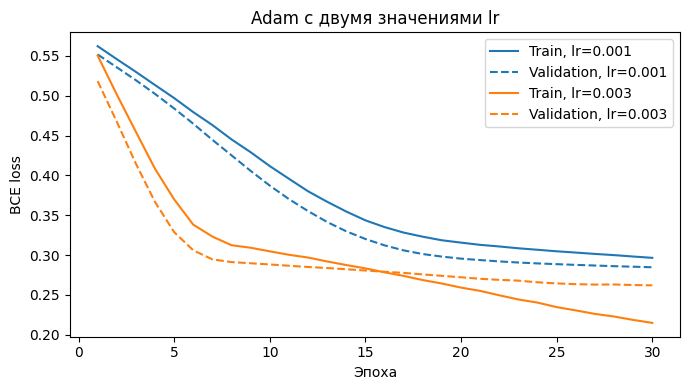

In [7]:
epoch_numbers = range(1, epochs + 1)
plt.figure(figsize=(7, 4))
plt.plot(epoch_numbers, train_a, color="tab:blue", label="Train, lr=0.001")
plt.plot(epoch_numbers, val_a, "--", color="tab:blue", label="Validation, lr=0.001")
plt.plot(epoch_numbers, train_b, color="tab:orange", label="Train, lr=0.003")
plt.plot(epoch_numbers, val_b, "--", color="tab:orange", label="Validation, lr=0.003")
plt.xlabel("Эпоха")
plt.ylabel("BCE loss")
plt.title("Adam с двумя значениями lr")
plt.legend()
plt.tight_layout()
plt.show()

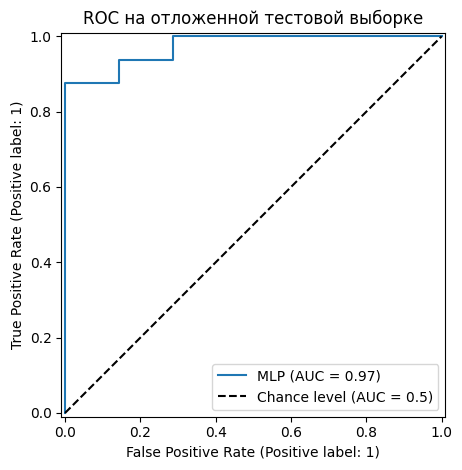

Test ROC-AUC: 0.973


In [8]:
best_model.eval()
with torch.inference_mode():
    scores = torch.sigmoid(best_model(X_test)).ravel().numpy()

roc = RocCurveDisplay.from_predictions(
    y_test.ravel().numpy(), scores, name="MLP", plot_chance_level=True
)
plt.title("ROC на отложенной тестовой выборке")
plt.tight_layout()
plt.show()
print(f"Test ROC-AUC: {roc.roc_auc:.3f}")

In [9]:
# После проверки на test обучаем новую модель на всех очищенных строках.
age_mean = float(inputs["AGE"].mean())
age_std = float(inputs["AGE"].std(ddof=0))
X_full = scale_features(age_mean, age_std)

final_model, final_losses, _ = train_model(X_full, y, lr=best_lr)
final_model.eval()
print(f"Финальное обучение: {len(X_full)} строк, loss = {final_losses[-1]:.4f}")

Финальное обучение: 274 строк, loss = 0.1899


In [10]:
preprocessing = {
    "feature_columns": features.tolist(),
    "age_mean": age_mean,
    "age_std": age_std,
}

torch.save(
    {"model_state_dict": final_model.state_dict(), **preprocessing},
    "pytorch_cancer_model.pt",
)

# Полная модель принимает подготовленные признаки и возвращает логиты.
batch = torch.export.Dim("batch", min=1)
exported = torch.export.export(
    final_model, (X_full[:2],), dynamic_shapes=({0: batch},), strict=False
)
torch.export.save(
    exported, "pytorch_cancer_full_model.pt2",
    extra_files={"preprocessing.json": json.dumps(preprocessing)},
)
print("Сохранены веса (.pt) и полная модель (.pt2).")

Сохранены веса (.pt) и полная модель (.pt2).
